# 2. A CNN from Scratch

Practice for module 2: convolution via im2col, handcrafted vs learned filters, output-size formula,
max-pooling forward/backward, softmax + cross-entropy, a full manual backward pass checked
numerically, and training a tiny CNN on synthetic images.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 2.1 Convolution as matrix multiplication (im2col)

Every k×k×C patch becomes one row; all filters become columns. One matmul computes all output maps.
Output size: `(in + 2p - k) / s + 1`.

In [2]:
def out_size(n, k, s=1, p=0):
    return (n + 2 * p - k) // s + 1

def im2col(x, k, s=1, p=0):
    """x: (C, H, W) -> (out_h*out_w, C*k*k)"""
    C, H, W = x.shape
    x = np.pad(x, ((0, 0), (p, p), (p, p)))
    oh, ow = out_size(H, k, s, p), out_size(W, k, s, p)
    cols = np.empty((oh * ow, C * k * k))
    for i in range(oh):
        for j in range(ow):
            cols[i * ow + j] = x[:, i * s:i * s + k, j * s:j * s + k].ravel()
    return cols, oh, ow

def conv2d(x, w, b, s=1, p=0):
    """x: (C, H, W), w: (F, C, k, k) -> (F, oh, ow)"""
    F, C, k, _ = w.shape
    cols, oh, ow = im2col(x, k, s, p)
    out = cols @ w.reshape(F, -1).T + b
    return out.T.reshape(F, oh, ow)

for (n, k, s, p) in [(28, 3, 1, 0), (28, 3, 1, 1), (28, 5, 2, 2), (32, 4, 4, 0)]:
    print(f"in={n} k={k} s={s} p={p} -> out={out_size(n, k, s, p)}")

in=28 k=3 s=1 p=0 -> out=26
in=28 k=3 s=1 p=1 -> out=28
in=28 k=5 s=2 p=2 -> out=14
in=32 k=4 s=4 p=0 -> out=8


## 2.2 Handcrafted filters: Sobel on a synthetic RGB image

The filter depth equals the number of input channels (3); the number of filters (2) equals the number
of output feature maps.

filters: (2, 3, 3, 3) -> feature maps: (2, 32, 32) (padding=1 keeps 32x32)


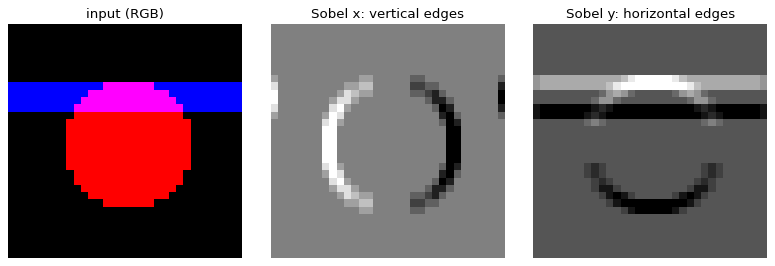

In [3]:
H = W = 32
yy, xx = np.mgrid[:H, :W]
img = np.zeros((3, H, W))
img[0][(xx - 16) ** 2 + (yy - 16) ** 2 < 80] = 1.0     # red disk
img[2][8:12, :] = 1.0                                   # blue horizontal bar

sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
w = np.stack([np.stack([sobel_x] * 3), np.stack([sobel_x.T] * 3)])   # (2, 3, 3, 3)
fmaps = conv2d(img, w, np.zeros(2), p=1)
print("filters:", w.shape, "-> feature maps:", fmaps.shape, "(padding=1 keeps 32x32)")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
axes[0].imshow(img.transpose(1, 2, 0)); axes[0].set_title("input (RGB)")
axes[1].imshow(fmaps[0], cmap="gray"); axes[1].set_title("Sobel x: vertical edges")
axes[2].imshow(fmaps[1], cmap="gray"); axes[2].set_title("Sobel y: horizontal edges")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 2.3 Max-pooling: forward keeps argmax indices, backward routes the gradient there

In [4]:
def maxpool_forward(x, k=2):
    C, H, W = x.shape
    xr = x.reshape(C, H // k, k, W // k, k).transpose(0, 1, 3, 2, 4).reshape(C, H // k, W // k, k * k)
    idx = xr.argmax(-1)
    return xr.max(-1), idx

def maxpool_backward(dout, idx, shape, k=2):
    C, H, W = shape
    dx = np.zeros((C, H // k, W // k, k * k))
    np.put_along_axis(dx, idx[..., None], dout[..., None], axis=-1)
    return dx.reshape(C, H // k, W // k, k, k).transpose(0, 1, 3, 2, 4).reshape(shape)

x = rng.integers(0, 10, size=(1, 4, 4)).astype(float)
pooled, idx = maxpool_forward(x)
dx = maxpool_backward(np.ones_like(pooled), idx, x.shape)
print("input:\n", x[0]); print("pooled:\n", pooled[0])
print("gradient (1 only at each window max):\n", dx[0])
print("pooling has no parameters; it just halves H and W:", x.shape, "->", pooled.shape)

input:
 [[8. 6. 5. 2.]
 [3. 0. 0. 0.]
 [1. 8. 6. 9.]
 [5. 6. 9. 7.]]
pooled:
 [[8. 5.]
 [8. 9.]]
gradient (1 only at each window max):
 [[1. 0. 1. 0.]
 [0. 0. 0. 0.]
 [0. 1. 0. 1.]
 [0. 0. 0. 0.]]
pooling has no parameters; it just halves H and W: (1, 4, 4) -> (1, 2, 2)


## 2.4 Softmax + cross-entropy: gradient wrt logits is `p - y`

In [5]:
def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

def cross_entropy(z, label):
    return -np.log(softmax(z)[label])

z = np.array([1.0, 2.0, 0.5]); label = 0
analytic = softmax(z) - np.eye(3)[label]
eps = 1e-6
numeric = np.array([(cross_entropy(z + eps * e, label) - cross_entropy(z - eps * e, label)) / (2 * eps)
                    for e in np.eye(3)])
print("p:", softmax(z), "sum =", softmax(z).sum())
print("p - y   :", analytic); print("numeric :", numeric)

p: [0.231 0.629 0.14 ] sum = 1.0
p - y   : [-0.769  0.629  0.14 ]
numeric : [-0.769  0.629  0.14 ]


## 2.5 Tiny CNN: conv -> ReLU -> maxpool -> linear -> softmax

Conv backward via im2col: `dW = dout^T · cols` sums the contributions of all windows (weight sharing);
`dcols` is scattered back with col2im, where overlapping positions are summed.

In [6]:
def col2im(dcols, shape, k, s=1, p=0):
    C, H, W = shape
    dx = np.zeros((C, H + 2 * p, W + 2 * p))
    oh, ow = out_size(H, k, s, p), out_size(W, k, s, p)
    for i in range(oh):
        for j in range(ow):
            dx[:, i * s:i * s + k, j * s:j * s + k] += dcols[i * ow + j].reshape(C, k, k)
    return dx[:, p:p + H, p:p + W]

class TinyCNN:
    def __init__(self, F=4, k=3, size=12, n_cls=2):
        self.k = k
        self.w = rng.normal(0, 0.3, (F, 1, k, k)); self.b = np.zeros(F)
        n_feat = F * (size // 2) ** 2
        self.W = rng.normal(0, 0.1, (n_feat, n_cls)); self.c = np.zeros(n_cls)

    def forward(self, x):
        F = self.w.shape[0]
        self.x = x
        self.cols, oh, ow = im2col(x, self.k, p=1)
        z = (self.cols @ self.w.reshape(F, -1).T + self.b).T.reshape(F, oh, ow)
        self.z = z
        a = np.maximum(0, z)
        self.pooled, self.idx = maxpool_forward(a)
        self.flat = self.pooled.ravel()
        return self.flat @ self.W + self.c

    def backward(self, dlogits):
        F = self.w.shape[0]
        g = {"W": np.outer(self.flat, dlogits), "c": dlogits}
        dpool = (self.W @ dlogits).reshape(self.pooled.shape)
        da = maxpool_backward(dpool, self.idx, self.z.shape)
        dz = da * (self.z > 0)                                 # ReLU backward
        dz_flat = dz.reshape(F, -1).T                          # (positions, F)
        g["w"] = (dz_flat.T @ self.cols).reshape(self.w.shape) # summed over all windows
        g["b"] = dz_flat.sum(0)
        g["x"] = col2im(dz_flat @ self.w.reshape(F, -1), self.x.shape, self.k, p=1)
        return g

def loss_fn(net, x, label):
    return cross_entropy(net.forward(x), label)

net = TinyCNN()
x = rng.normal(size=(1, 12, 12)); label = 1
logits = net.forward(x)
grads = net.backward(softmax(logits) - np.eye(2)[label])

def numeric_grad(param, picks, eps=1e-5):
    out = []
    for i in picks:
        old = param[i]
        param[i] = old + eps; lp = loss_fn(net, x, label)
        param[i] = old - eps; lm = loss_fn(net, x, label)
        param[i] = old
        out.append((lp - lm) / (2 * eps))
    return np.array(out)

for name, param in [("w", net.w), ("W", net.W), ("x", x)]:
    picks = [np.unravel_index(i, param.shape) for i in rng.choice(param.size, 5, replace=False)]
    num = numeric_grad(param, picks)
    ana = np.array([grads[name][i] for i in picks])
    print(f"grad check {name}: max abs diff = {np.abs(num - ana).max():.2e}")

grad check w: max abs diff = 8.13e-12
grad check W: max abs diff = 3.94e-12
grad check x: max abs diff = 7.08e-12


## 2.6 Training on synthetic images: horizontal vs vertical bars

The network learns its own filters; after training they look like edge/bar detectors.

epoch losses: [0.31  0.029 0.013 0.008 0.006 0.004 0.003 0.003]
test accuracy: 1.0


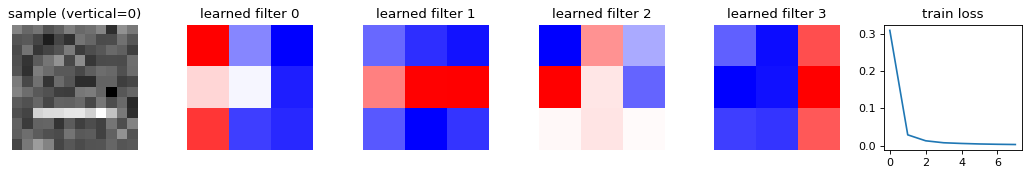

In [7]:
def make_bar(vertical, size=12):
    im = rng.normal(0, 0.2, (1, size, size))
    pos, length = rng.integers(2, size - 2), rng.integers(5, size)
    start = rng.integers(0, size - length + 1)
    if vertical: im[0, start:start + length, pos] += 1
    else:        im[0, pos, start:start + length] += 1
    return im

labels = rng.integers(0, 2, 400)
data = np.stack([make_bar(v) for v in labels])
Xtr, ytr, Xte, yte = data[:300], labels[:300], data[300:], labels[300:]

net = TinyCNN()
lr, hist = 0.05, []
for epoch in range(8):
    total = 0
    for i in rng.permutation(len(Xtr)):
        logits = net.forward(Xtr[i])
        total += cross_entropy(logits, ytr[i])
        g = net.backward(softmax(logits) - np.eye(2)[ytr[i]])
        for p in ["w", "b", "W", "c"]:
            setattr(net, p, getattr(net, p) - lr * g[p])
    hist.append(total / len(Xtr))
test_acc = np.mean([net.forward(x).argmax() == y for x, y in zip(Xte, yte)])
print("epoch losses:", np.round(hist, 3)); print("test accuracy:", test_acc)

fig, axes = plt.subplots(1, 6, figsize=(13, 2.3))
axes[0].imshow(Xte[0, 0], cmap="gray"); axes[0].set_title(f"sample (vertical={yte[0]})")
for f in range(4):
    axes[f + 1].imshow(net.w[f, 0], cmap="bwr"); axes[f + 1].set_title(f"learned filter {f}")
axes[5].plot(hist); axes[5].set_title("train loss")
for a in axes[:5]: a.axis("off")
plt.tight_layout(); plt.show()